# Tutorial: Public Xenium Breast Cancer Data

Here we take the publicly available 10x Xenium FFPE human breast cancer sections from {cite}`Janesick2023`.
The tissue contains ductal carcinoma in situ (DCIS) and invasive tumor, so there are plenty of ducts with lumens, and the authors' supervised cell-type annotations give us the epithelial cells that line them.

We will see how to use the auto settings, which differ from {cite}`Reyes2026`, but help the method generalize to new datasets instead of being hand-curated.

In [3]:
import anndata as ad
import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spatialdata_io
from anndata.acc import A
from pathlib import Path

import seq_lumen
from seq_lumen import Quantifier

centroids_acc = A.obsm["spatial"]
border_acc = A.obs["is_epithelial"]
annotation_acc = A.obs["cell_annotation"]
sample_acc = A.obs["sample_id"]

Each replicate's full Xenium output bundle is ~10 GB, mostly images and transcripts.
We only need the cell table, so we pull just the files [`spatialdata_io.xenium`](https://spatialdata.scverse.org/projects/io/en/latest/generated/spatialdata_io.xenium.html) reads for it out of the remote zip via HTTP range requests (~330 MB per replicate), and cache them locally.
Cell types come from the supervised annotation sheets, keyed by Xenium `cell_id`.

In [4]:
URL = "https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_{rep}/Xenium_FFPE_Human_Breast_Cancer_{rep}_outs.zip"
ANNOTATIONS_URL = (
    "https://cdn.10xgenomics.com/raw/upload/v1695234604/Xenium%20Preview%20Data/Cell_Barcode_Type_Matrices.xlsx"
)
FILES = ["experiment.xenium", "cells.parquet", "cells.zarr.zip", "cell_feature_matrix.h5"]
CACHE = Path.home() / ".cache" / "seq_lumen" / "xenium_breast"


def load(rep: str, annotations: pd.DataFrame) -> ad.AnnData:
    """Fetch only the files needed for one replicate's cell table and read it, with cell types."""
    out = CACHE / rep
    out.mkdir(parents=True, exist_ok=True)
    zf = fsspec.filesystem("zip", fo=fsspec.open(URL.format(rep=rep), block_size=2**20).open())
    for f in FILES:
        if not (out / f).exists():
            zf.get(f"outs/{f}", str(out / f))
    sdata = spatialdata_io.xenium(
        out,
        cells_boundaries=False,
        nucleus_boundaries=False,
        cells_labels=False,
        nucleus_labels=False,
        transcripts=False,
        morphology_mip=False,
        morphology_focus=False,
        aligned_images=False,
    )
    table = sdata["table"]
    table.obs[annotation_acc.idx] = table.obs["cell_id"].map(annotations.set_index("Barcode")["Cluster"]).values
    return table


annotations = pd.read_excel(ANNOTATIONS_URL, sheet_name=None)
adata_full = ad.concat(
    {rep: load(rep, annotations[f"Xenium R{rep[-1]} Fig1-5 (supervised)"]) for rep in ["Rep1", "Rep2"]},
    label="sample_id",
    index_unique="-",
)

/home/goldi1/.local/share/hatch/env/virtual/seq-lumen/3L2DjH0z/docs/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/goldi1/.local/share/hatch/env/virtual/seq-lumen/3L2DjH0z/docs/lib/python3.14/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'cell_labels', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/goldi1/.local/share/hatch/env/virtual/seq-lumen/3L2DjH0z/docs/lib/python3.14/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'cell_labels', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


In [5]:
sample_id = "Rep1"
adata_sample = adata_full[adata_full[sample_acc] == sample_id].copy()

Lumens are lined by luminal (DCIS/tumor) cells wrapped by myoepithelial cells, so all of these count as border cells.

In [6]:
adata_sample.obs[border_acc.idx] = adata_sample[annotation_acc].isin(
    ["DCIS_1", "DCIS_2", "Invasive_Tumor", "Prolif_Invasive_Tumor", "Myoepi_ACTA2+", "Myoepi_KRT15+"]
)
centroids = adata_sample[centroids_acc]
border_centroids = adata_sample[adata_sample[border_acc]][centroids_acc]


## Parameter Choice

The default parameters of {class}`~seq_lumen.Quantifier` are those from {cite}`Reyes2026`, but we *strongly* encourage using {meth}`seq_lumen.Quantifier.from_adata`. This method uses a small auto-discovery method that likely aligns better with user expectations. It also automatically uses a small fix for not calling luminal areas on the outer boundary of the sample among other bug fixes.

First, we start by simply finding the `xy` coordinates of the luminal "holes" on a single sample, although {class}`~seq_lumen.Quantifier`'s {meth}`~seq_lumen.Quantifier.find`, {meth}`~seq_lumen.Quantifier.count`, {meth}`~seq_lumen.Quantifier.assign`, and {meth}`~seq_lumen.Quantifier.__call__` (i.e., run everything) each offer the ability to loop through multiple samples at once via their `sample_acc` argument. 

{meth}`~seq_lumen.Quantifier.from_adata` will autodiscover the underlying params for lumen identification based on properties of the centroids from _all available samples_ (here both replicates) as this enables more unbiased cross-sample identification/comparison (rather than having each sample get its own parameter).

100%|██████████| 5/5 [00:00<00:00,  9.17it/s]


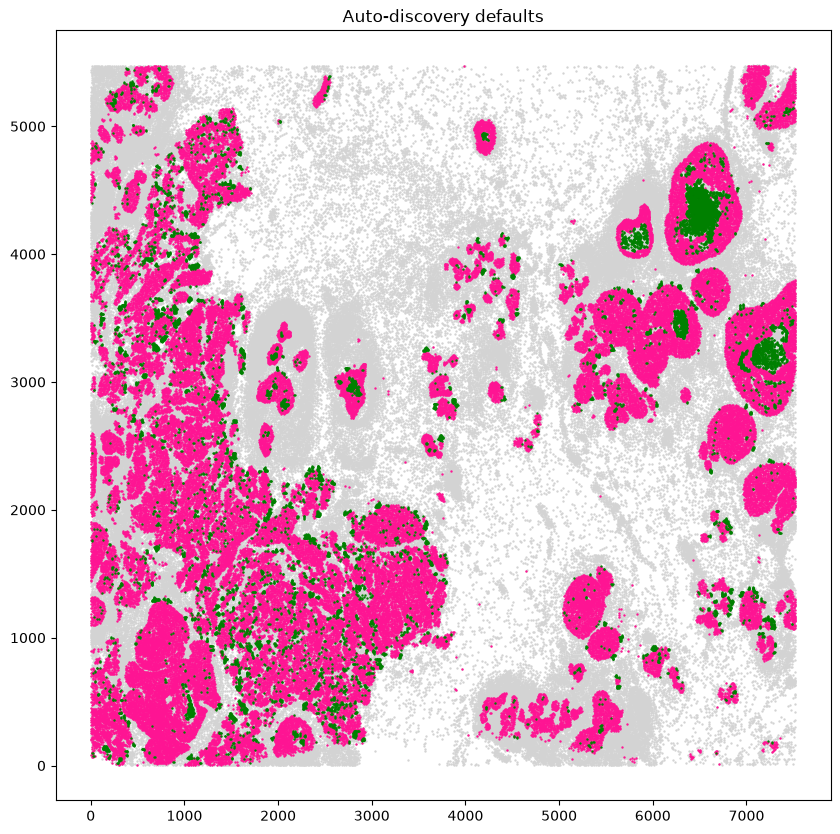

In [7]:
sl_auto = Quantifier.from_adata(
    adata_full,
    centroids_acc=centroids_acc,
    sample_acc=sample_acc,
)
lumen_auto = sl_auto.find(adata_sample, centroids_acc=centroids_acc, border_acc=border_acc)
plt.figure(figsize=[10, 10])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c="lightgray")
plt.scatter(border_centroids[:, 0], border_centroids[:, 1], s=0.5, c="deeppink")
plt.scatter(lumen_auto[:, 0], lumen_auto[:, 1], s=0.5, c="green")
plt.title("Auto-discovery defaults")
plt.show()

The defaults call lumen along the sparse stroma surrounding nearly every epithelial nest, whereas the auto-discovered parameters mostly restrict lumen to the centers of the DCIS ducts.

## Lumen Scores

Users are likely more interested in a final "score" they can correlate with types and features.

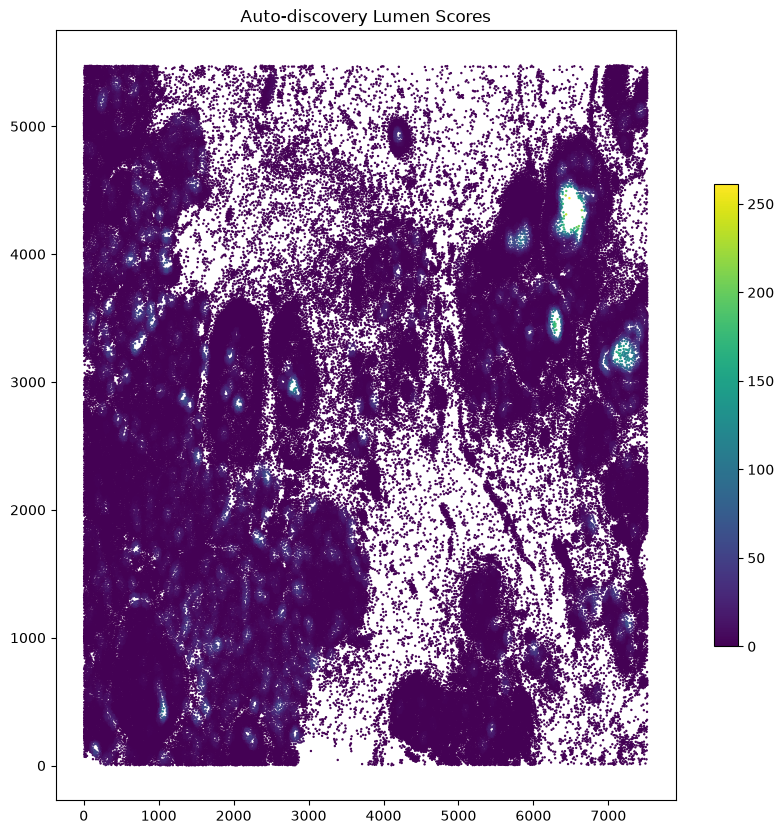

In [8]:
sl_auto.count(adata_sample, lumen_auto, centroids_acc=centroids_acc)
plt.figure(figsize=[10, 10])
plt.scatter(centroids[:, 0], centroids[:, 1], s=0.5, c=np.array(adata_sample[seq_lumen.acc.count_acc]))
plt.colorbar(shrink=0.6)
plt.title("Auto-discovery Lumen Scores")
plt.show()

Here we track the lumen score by cell type to see which types are enriched for being lumen-proximal.

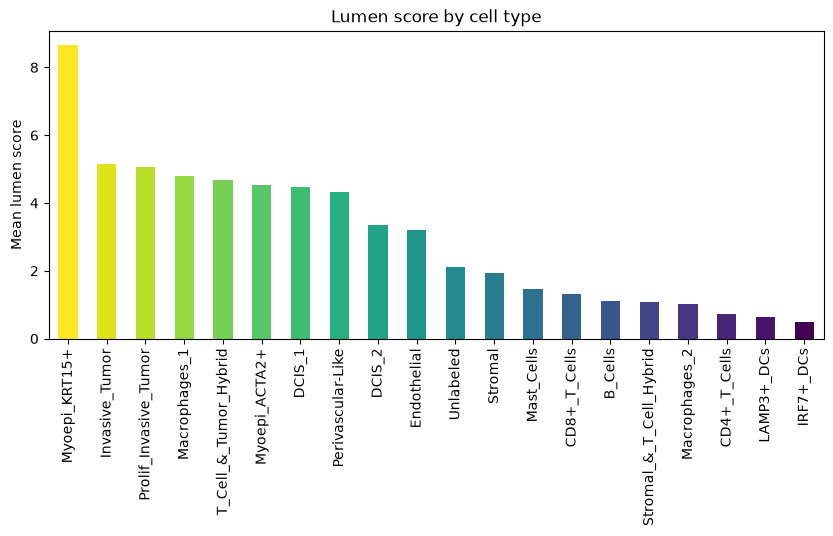

In [9]:
scores = pd.Series(adata_sample[seq_lumen.acc.count_acc], index=adata_sample.obs_names)
by_type = scores.groupby(adata_sample[annotation_acc], observed=True).mean().sort_values(ascending=False)
plt.figure(figsize=[10, 4])
by_type.plot.bar(color=plt.cm.viridis(np.linspace(1, 0, len(by_type))))
plt.ylabel("Mean lumen score")
plt.title("Lumen score by cell type")
plt.show()

Similarly, we can track gene expression against lumen score to identify genes correlated with presence of lumen.

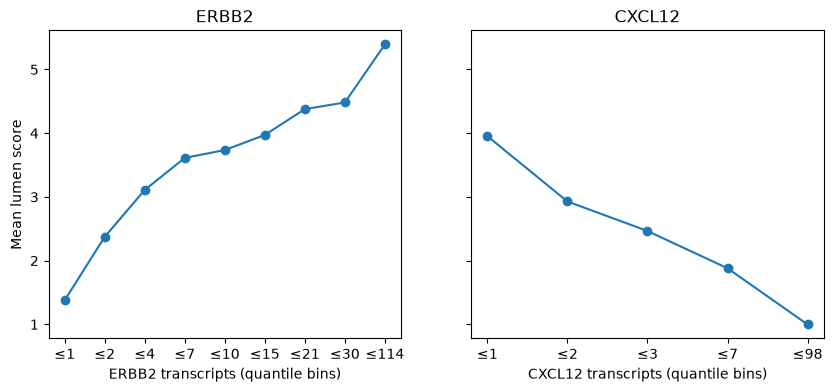

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=[10, 4], sharey=True)
for ax, gene in zip(axes, ["ERBB2", "CXCL12"], strict=True):
    expr = adata_sample[A.X[:, gene]]
    expr_bin = pd.qcut(expr, 10, duplicates="drop")
    scores.groupby(expr_bin, observed=True).mean().plot(ax=ax, marker="o")
    ax.set_xticks(range(len(expr_bin.categories)), [f"≤{b.right:g}" for b in expr_bin.categories])
    ax.set_xlabel(f"{gene} transcripts (quantile bins)")
    ax.set_title(gene)
axes[0].set_ylabel("Mean lumen score")
plt.show()

## Lumen IDs

Finally, users may be interested in which lumen a given cell borders.

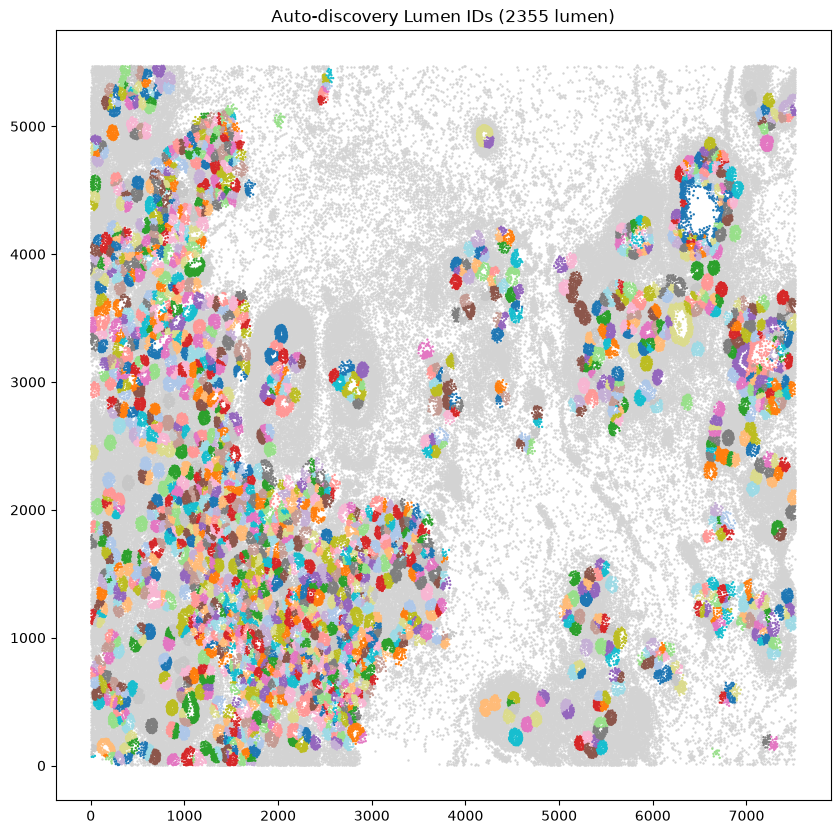

In [11]:
sl_auto.assign(adata_sample, lumen_auto, centroids_acc=centroids_acc)
ids = np.array(adata_sample[seq_lumen.acc.assignment_acc])
has_lumen = ids >= 0
# Shuffle ids so neighbouring lumen get distinguishable colors.
colors = np.random.default_rng(0).permutation(ids.max() + 1)[ids[has_lumen]]
plt.figure(figsize=[10, 10])
plt.scatter(centroids[~has_lumen, 0], centroids[~has_lumen, 1], s=0.5, c="lightgray")
plt.scatter(centroids[has_lumen, 0], centroids[has_lumen, 1], s=0.5, c=colors, cmap="tab20")
plt.title(f"Auto-discovery Lumen IDs ({ids.max() + 1} lumen)")
plt.show()